# Unit 4 · Lecture 6 — ACTIVITY
## Case study: *MediCover AutoClaim* — explaining and monitoring an AI claim-approval model
**Course:** UE24CS342AA9 — Visualization of Data, Understanding and Interpretation

**Name:** ____________________  **SRN:** ____________________  **Section:** ____

---
### The case
**MediCover** is a (fictional) Indian health insurer. Since January it has used **AutoClaim**, a gradient-boosted model that predicts whether a hospital claim is **legitimate** (`legit = 1`). Claims with `P(legit) ≥ 0.5` are paid automatically; the rest go to a human investigator, which delays payment by about three weeks.

Three things have happened:

1. **A complaint.** Mrs. Lakshmi Iyer (claim **C-1042**, ₹68,000, knee surgery) was sent to investigation. She has asked *"Why was my claim not approved, and what can I do?"* The IRDAI (regulator) guidelines require MediCover to answer in plain language.
2. **An audit.** The internal audit team wants to know **what the model has learned overall** and whether it relies on anything it should not.
3. **An incident.** Over the last ten weeks of live operation the operations team feels that *"something is off"*: more customers are complaining about rejections and the fraud team has started seeing suspicious approvals.

You are the new **ML visual-analytics analyst**. Work through Parts A–G. 



### How to work
* Cells marked **`# TODO`** are yours. Replace the `None` values / fill the function bodies.
* After each task a **check cell** prints ✅ / ❌ / ⏳ (not attempted). .
* Run the notebook **top to bottom**. Do **not** edit the *Toolkit* cell.
* Libraries: `numpy`, `pandas`, `matplotlib`, `scikit-learn` (optional: `ipywidgets`). The data are **synthetic**, generated in the toolkit, so no download is needed.

---
## 0 · Toolkit — run this, do not edit
Generates the historical claims, trains AutoClaim, simulates 10 weeks of production, and defines helper functions (`exact_shap`, `waterfall`, `psi`, `grade`).

In [1]:
import itertools, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import factorial
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
NAVY, ORANGE, GREEN, RED, GREY = "#2F5597", "#ED7D31", "#70AD47", "#C00000", "#7F7F7F"
POS, NEG = "#D9534F", "#2F7FC1"

FEATURES = ["claim_amount_k", "patient_age", "policy_years", "prior_claims",
            "doc_score", "days_to_submit", "hospital_tier", "policy_type"]
M = len(FEATURES)
POLICY = {0: "Standard", 1: "Senior-Care"}

def true_logit(df):
    age_eff = np.where(df.policy_type == 1, 0.045, -0.045) * (df.patient_age - 45)
    return 1.6 * (0.9 + 4.0 * (df.doc_score - 0.6) - 1.1 * np.log(df.claim_amount_k / 25)
                  + 0.12 * np.minimum(df.policy_years, 10) - 0.45 * df.prior_claims
                  - 0.05 * (df.days_to_submit - 7) + age_eff)

def make_claims(n, rng):
    age = rng.integers(18, 86, n)
    ptype = np.where(age >= 55, rng.random(n) < 0.7, rng.random(n) < 0.08).astype(int)
    tier = rng.choice([1, 2, 3, 4], n, p=[0.30, 0.30, 0.25, 0.15])
    # bigger hospitals bill more -> hospital_tier is a PROXY for claim size (no direct effect on legitimacy)
    claim = np.round(np.exp(rng.normal(np.log(60) - 0.35 * (tier - 1), 0.6, n)), 1)
    df = pd.DataFrame({
        "claim_amount_k": np.clip(claim, 2, 900),
        "patient_age": age,
        "policy_years": rng.integers(0, 16, n),
        "prior_claims": rng.poisson(0.8, n),
        "doc_score": np.round(np.clip(rng.beta(5, 3, n), 0, 1), 2),
        "days_to_submit": rng.integers(0, 31, n),
        "hospital_tier": tier,
        "policy_type": ptype})
    df["legit"] = (rng.random(n) < 1 / (1 + np.exp(-true_logit(df)))).astype(int)
    return df

def production_week(week, seed=100):
    rng = np.random.default_rng(seed + week)
    n = 150 if week == 4 else 1200            # week 4: Diwali holiday -> very few claims
    df = make_claims(n, rng)
    if week >= 8:                              # new fraud ring: perfect paperwork, filed within a day
        k = int(0.15 * n)
        ring = make_claims(k, rng)
        ring["doc_score"] = np.round(rng.uniform(0.85, 0.98, k), 2)
        ring["days_to_submit"] = rng.integers(0, 2, k)
        ring["prior_claims"] = 0
        ring["legit"] = 0
        df = pd.concat([df, ring], ignore_index=True)
    df["week"] = week
    if week >= 6:                              # billing-feed bug: Tier-4 hospitals send amounts in rupees instead of ₹ thousand
        bug = df.hospital_tier == 4
        df.loc[bug, "claim_amount_k"] = df.loc[bug, "claim_amount_k"] * 1000
    return df.sample(frac=1, random_state=week).reset_index(drop=True)


# ---------------- historical data and the AutoClaim model ----------------
data = make_claims(8000, np.random.default_rng(7))
X, y = data[FEATURES], data["legit"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
model = GradientBoostingClassifier(n_estimators=250, max_depth=3, learning_rate=0.05, random_state=0).fit(X_tr, y_tr)
predict = lambda A: model.predict_proba(pd.DataFrame(np.asarray(A, float), columns=FEATURES))[:, 1]

# ---------------- the complaint: claim C-1042 ----------------
C1042 = pd.Series(dict(claim_amount_k=68.0, patient_age=62, policy_years=3, prior_claims=1, doc_score=0.48,
                       days_to_submit=12, hospital_tier=2, policy_type=1), name="C-1042")[FEATURES].astype(float)
P1042 = predict([C1042])[0]

# ---------------- exact Shapley values (2^8 = 256 coalitions) ----------------
MASKS = np.array([[(s >> j) & 1 for j in range(M)] for s in range(2 ** M)], dtype=bool)
SIZES = MASKS.sum(1)
background = X_tr.sample(60, random_state=3).to_numpy(float)
_W = np.array([factorial(s) * factorial(M - s - 1) / factorial(M) for s in range(M)])

def exact_shap(x, predict_fn=predict, bg=background):
    """Exact interventional SHAP values of one instance x (probability scale). Returns (base, phi)."""
    x = np.asarray(x, float)
    Z = np.where(MASKS[:, None, :], x, bg[None, :, :])
    v = predict_fn(Z.reshape(-1, M)).reshape(len(MASKS), -1).mean(1)
    idx = {tuple(m): k for k, m in enumerate(map(tuple, MASKS))}
    phi = np.zeros(M)
    for i in range(M):
        for k, m in enumerate(MASKS):
            if m[i]:
                continue
            mi = m.copy(); mi[i] = True
            phi[i] += _W[SIZES[k]] * (v[idx[tuple(mi)]] - v[k])
    return v[0], phi

def waterfall(base, phi, x, title="", top=8, threshold=0.5):
    order = np.argsort(np.abs(phi))[::-1][:top]
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(order) + 1.6))
    cum = base
    for k, j in enumerate(order):
        yy = len(order) - 1 - k
        ax.barh(yy, phi[j], left=cum, color=POS if phi[j] > 0 else NEG, height=0.6)
        ax.text(cum + phi[j] + (0.004 if phi[j] > 0 else -0.004), yy, f"{phi[j]:+.3f}",
                va="center", ha="left" if phi[j] > 0 else "right", fontsize=9)
        cum += phi[j]
    ax.set_yticks(range(len(order)), [f"{FEATURES[j]} = {np.asarray(x)[j]:g}" for j in order][::-1])
    ax.axvline(base, color=GREY, ls="--", lw=1)
    ax.axvline(threshold, color=RED, ls=":", lw=1)
    cums = base + np.concatenate([[0], np.cumsum(phi[order])])
    ax.set_xlim(min(cums.min(), threshold) - 0.06, max(cums.max(), threshold) + 0.06)
    ax.set_xlabel("P(legit)")
    ax.set_title(f"{title}\nbase {base:.2f} + Σφ = {base + phi.sum():.2f}", loc="left")
    plt.tight_layout(); plt.show()

def psi(expected, actual, bins=10):
    """Population Stability Index between a reference sample and a new sample."""
    edges = np.quantile(expected, np.linspace(0, 1, bins + 1)); edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected) + 1e-6
    a = np.histogram(actual, edges)[0] / len(actual) + 1e-6
    return float(np.sum((a - e) * np.log(a / e)))

# ---------------- ten weeks of production ----------------
stream = pd.concat([production_week(w) for w in range(1, 11)], ignore_index=True)
stream["p"] = predict(stream[FEATURES])
stream["pred"] = (stream.p >= 0.5).astype(int)
stream["error"] = (stream.pred != stream.legit).astype(int)

# ---------------- auto-grader ----------------
RESULTS = {}
def grade(qid, marks, value, test, hint=""):
    if value is None:
        RESULTS[qid] = (0, marks); print(f"⏳ {qid}: not attempted yet ({marks} marks)"); return
    try:
        ok = bool(test(value))
    except Exception as e:
        ok, hint = False, f"{hint} [error: {type(e).__name__}: {e}]"
    RESULTS[qid] = (marks if ok else 0, marks)
    print(f"✅ {qid}: correct (+{marks})" if ok else f"❌ {qid}: not yet — hint: {hint}")

print(f"Training rows: {len(X_tr)}, test accuracy = {accuracy_score(y_te, model.predict(X_te)):.3f}, "
      f"AUC = {roc_auc_score(y_te, model.predict_proba(X_te)[:, 1]):.3f}")
print(f"Production stream: {len(stream)} claims over 10 weeks")
print(f"Claim C-1042: P(legit) = {P1042:.3f} -> {'auto-approved' if P1042 >= 0.5 else 'sent to investigation'}")

Training rows: 6000, test accuracy = 0.812, AUC = 0.874
Production stream: 11490 claims over 10 weeks
Claim C-1042: P(legit) = 0.419 -> sent to investigation


### Data dictionary
| Feature | Meaning | Can the customer change it? |
|---|---|---|
| `claim_amount_k` | claimed amount, ₹ thousand | partly (co-pay / claim only eligible items, min 50 % of original) |
| `patient_age` | age in years | no |
| `policy_years` | years the policy has been held | no |
| `prior_claims` | number of earlier claims | no |
| `doc_score` | completeness of uploaded documents, 0–1 (OCR checklist) | **yes** (upload missing bills, discharge summary) |
| `days_to_submit` | days between discharge and claim | no (already submitted) |
| `hospital_tier` | 1 = metro super-speciality … 4 = small nursing home | no |
| `policy_type` | 0 = Standard, 1 = Senior-Care | no |

In [2]:
display(data.head())
print(data.describe().round(2).T[["mean", "std", "min", "max"]])

,claim_amount_k,patient_age,policy_years,prior_claims,doc_score,days_to_submit,hospital_tier,policy_type,legit
0,34.8,82,0,0,0.69,20,2,0,0
1,13.7,60,9,1,0.77,23,4,1,1
2,40.1,64,2,1,0.85,19,1,1,1
3,38.6,79,4,0,0.66,4,3,1,1
4,20.5,57,2,1,0.60,16,1,1,1


                 mean    std    min     max
claim_amount_k  48.51  38.26   2.70  555.50
patient_age     51.60  19.54  18.00   85.00
policy_years     7.44   4.60   0.00   15.00
prior_claims     0.80   0.90   0.00    6.00
doc_score        0.63   0.16   0.08    0.99
days_to_submit  15.08   8.99   0.00   30.00
hospital_tier    2.27   1.06   1.00    4.00
policy_type      0.36   0.48   0.00    1.00
legit            0.70   0.46   0.00    1.00


---
## Part A · Choosing the right XAI visualization 
Munzner's *what–why–how* framework says the **task** decides the idiom. For each stakeholder question below pick **one** method from this list:

`"SHAP waterfall"`, `"Permutation importance"`, `"Counterfactual"`, `"PDP + ICE"`, `"Surrogate tree"`, `"Control chart"`

In [3]:
# TODO A1 — fill in each value with one method name from the list
A1 = {
    "Q1 Mrs. Iyer: why was MY claim not approved?":                                   None,
    "Q2 Audit: which inputs drive the model's decisions overall?":                     None,
    "Q3 Mrs. Iyer: what would I need to change to be approved?":                       None,
    "Q4 Actuary: how does P(legit) change with age, and is it the same for everyone?": None,
    "Q5 Auditor: give me a few if-then rules that behave like the model":              None,
    "Q6 Ops lead: is this week's error rate unusually high, or just noise?":           None,
}

✍️ **A2 .** Which of Q1–Q6 ask for a **local** explanation and which for a **global** one? One line each.

*Your answer:*

In [4]:
_A1_KEY = ["SHAP waterfall", "Permutation importance", "Counterfactual", "PDP + ICE", "Surrogate tree", "Control chart"]
_vals = list(A1.values())
grade("A1", 4, None if all(v is None for v in _vals) else _vals,
      lambda v: sum(a == b for a, b in zip(v, _A1_KEY)) == 6,
      f"{sum(a == b for a, b in zip(_vals, _A1_KEY))}/6 correct — think about local vs global and explain vs monitor")

⏳ A1: not attempted yet (4 marks)


---
## Part B · Global feature importance 
The model exposes `model.feature_importances_` (**impurity / gain importance**, computed on the *training* data). The audit team wants a model-agnostic measure computed on **held-out** data: **permutation importance** — shuffle one column, measure how much accuracy drops.

### B1  — implement permutation importance

In [5]:
def permutation_importance_manual(model, X, y, n_repeats=5, seed=0):
    # TODO B1:
    #  1. baseline = accuracy of model on (X, y)
    #  2. for each feature f, repeat n_repeats times:
    #        copy X, shuffle column f with rng.permutation, drops.append(baseline - new accuracy)
    #  3. return a DataFrame indexed by feature with columns "mean" and "std" of the drops,
    #     sorted by "mean" descending
    rng = np.random.default_rng(seed)
    return None

perm = permutation_importance_manual(model, X_te, y_te)
perm

In [6]:
from sklearn.inspection import permutation_importance as _sk_pi
_ref = _sk_pi(model, X_te, y_te, n_repeats=5, random_state=0, scoring="accuracy")
_ref_top3 = set(pd.Series(_ref.importances_mean, FEATURES).nlargest(3).index)
grade("B1", 6, perm, lambda p: set(p["mean"].nlargest(3).index) == _ref_top3 and {"mean", "std"} <= set(p.columns),
      "top-3 features differ from the reference — are you measuring accuracy DROP on the test set?")

if perm is not None:
    imp = pd.Series(model.feature_importances_, FEATURES)
    order = perm.index[::-1]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    axes[0].barh(order, imp[order], color=GREY); axes[0].set_title("Impurity importance (training data)", loc="left")
    axes[1].barh(order, perm.loc[order, "mean"], xerr=2 * perm.loc[order, "std"], color=NAVY, capsize=3)
    axes[1].set_title("Permutation importance (test data, ±2 SD)", loc="left"); axes[1].set_xlabel("accuracy drop")
    plt.tight_layout(); plt.show()

⏳ B1: not attempted yet (6 marks)


✍️ **B2 .** Compare the two charts. (a) Name one feature whose rank differs between them. (b) Give two reasons why impurity importance can be misleading. (c) Why are the error bars on the permutation chart useful when you present this to the audit committee?

*Your answer:*

### B3  — the proxy problem
Compliance argues that `claim_amount_k` "penalises expensive treatment" and asks for a model **without** it. The cell below trains `model_lite` without that column. Run your permutation function on it.

In [7]:
LITE = [f for f in FEATURES if f != "claim_amount_k"]
model_lite = GradientBoostingClassifier(n_estimators=250, max_depth=3, learning_rate=0.05, random_state=0).fit(X_tr[LITE], y_tr)
perm_lite = None if perm is None else permutation_importance_manual(model_lite, X_te[LITE], y_te)
if perm_lite is not None:
    cmp = pd.DataFrame({"with claim_amount": perm["mean"], "without claim_amount": perm_lite["mean"]}).round(4)
    display(cmp.sort_values("with claim_amount", ascending=False))
    print("corr(hospital_tier, claim_amount_k) =", round(data.hospital_tier.corr(data.claim_amount_k), 2))

In [8]:
# TODO B3 — what happened to hospital_tier? Choose "a", "b", "c" or "d".
#  a) Its importance stayed ~0: the model never uses hospital tier.
#  b) Its importance rose: hospital_tier is correlated with claim size, so the model now uses it as a PROXY.
#  c) Its importance rose because hospital tier directly causes fraud in the data-generating process.
#  d) Its importance fell, because removing a feature always lowers every other feature's importance.
B3 = None

In [9]:
grade("B3", 3, B3, lambda v: str(v).lower().strip() == "b",
      "check the table: did hospital_tier's importance change? The toolkit says tier has NO direct effect on legitimacy")

⏳ B3: not attempted yet (3 marks)


✍️ **B3b .** Explain to the compliance officer, in 3–4 sentences, why *dropping* a sensitive column does not guarantee the model stops using that information, and what visual check you would add to the monitoring dashboard because of this.

*Your answer:*

---
## Part C · Local explanations: SHAP and LIME 

### C1  — Shapley values by hand
To warm up, suppose only two features matter for C-1042: **D** = `doc_score` and **A** = `claim_amount_k`. Averaging the model over the background data gives these coalition values (P(legit) when only the features in the coalition are set to Mrs. Iyer's values):

| coalition S | ∅ | {D} | {A} | {D, A} |
|---|---|---|---|---|
| v(S) | 0.70 | 0.52 | 0.66 | 0.42 |

Using φᵢ = Σ over orderings of the marginal contribution, averaged (two orderings: D-first and A-first), compute φ_D and φ_A. Check that φ_D + φ_A = v({D,A}) − v(∅).

In [10]:
# TODO C1
phi_D = None
phi_A = None

In [11]:
grade("C1", 4, None if phi_D is None or phi_A is None else (phi_D, phi_A),
      lambda v: abs(v[0] + 0.21) < 1e-3 and abs(v[1] + 0.07) < 1e-3,
      "average each feature's marginal contribution over the two orderings (D,A) and (A,D)")

⏳ C1: not attempted yet (4 marks)


### C2  — exact SHAP for claim C-1042
Use the toolkit function `exact_shap(x)` (returns `(base, phi)`) on `C1042`. Then verify **local accuracy** (additivity): base + Σφ must equal the model's prediction `P1042`.

In [12]:
# TODO C2
base_1042, phi_1042 = None, None          # call exact_shap
additivity_gap = None                     # base + sum(phi) - P1042
C2_top_negative = None                    # name (string) of the feature that pushes C-1042 DOWN the most

In [13]:
grade("C2a", 3, additivity_gap, lambda g: abs(g) < 1e-6, "base + sum(phi) should reproduce P1042 exactly")
_b, _p = exact_shap(C1042)
grade("C2b", 3, C2_top_negative, lambda s: s == FEATURES[int(np.argmin(_p))], "look for the most negative φ")
if phi_1042 is not None:
    waterfall(base_1042, phi_1042, C1042, title="Claim C-1042 — SHAP waterfall")

⏳ C2a: not attempted yet (3 marks)
⏳ C2b: not attempted yet (3 marks)


### C3  — build LIME and test its stability
LIME fits a **weighted linear model** on perturbed copies of the instance. Complete the two TODO lines, then run LIME with 10 different random seeds.

In [14]:
SD = X_tr.std().to_numpy()

def lime_explain(x, n_samples=1500, kernel_width=0.75, seed=0):
    rng = np.random.default_rng(seed)
    x = np.asarray(x, float)
    Zs = rng.normal(0, 1, (n_samples, M))           # perturbations in SD units
    Z = x + Zs * SD                                 # perturbed claims in original units
    Z[:, FEATURES.index("hospital_tier")] = np.clip(np.round(Z[:, FEATURES.index("hospital_tier")]), 1, 4)
    Z[:, FEATURES.index("policy_type")] = (Z[:, FEATURES.index("policy_type")] > 0.5).astype(float)
    Z[:, 0] = np.clip(Z[:, 0], 2, None)
    preds = predict(Z)
    d = np.sqrt((Zs ** 2).sum(1)) / np.sqrt(M)      # distance from x
    weights = None   # TODO C3.1: exponential kernel  exp(-d^2 / kernel_width^2)
    coef = None      # TODO C3.2: fit Ridge(alpha=1.0) on (Zs, preds) with sample_weight=weights; coef = .coef_
    if weights is None or coef is None:
        return None
    return pd.Series(coef, FEATURES)                # effect of +1 SD of each feature on P(legit)

lime_1042 = lime_explain(C1042)
lime_1042

In [15]:
grade("C3a", 4, lime_1042, lambda s: s["doc_score"] > 0 and s["claim_amount_k"] < 0 and len(s) == M,
      "doc_score should get a positive coefficient and claim_amount a negative one — check weights and sample_weight")

if lime_1042 is not None:
    runs = pd.DataFrame([lime_explain(C1042, seed=s, n_samples=400) for s in range(10)])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].boxplot([runs[f] for f in FEATURES], vert=False); axes[0].set_yticks(range(1, M + 1), FEATURES)
    axes[0].axvline(0, color=GREY, lw=0.8); axes[0].set_title("LIME coefficients over 10 seeds (400 samples)", loc="left")
    if phi_1042 is not None:
        s = pd.Series(phi_1042, FEATURES)
        axes[1].barh(FEATURES, s, color=[POS if v > 0 else NEG for v in s]); axes[1].invert_yaxis()
        axes[1].set_yticks(range(M), FEATURES); axes[1].axvline(0, color=GREY, lw=0.8)
        axes[1].set_title("SHAP φ for C-1042 (exact, deterministic)", loc="left")
    plt.tight_layout(); plt.show()

⏳ C3a: not attempted yet (4 marks)


In [16]:
# TODO C3b — run LIME on C1042 with kernel_width = 0.25 and with kernel_width = 3.0 (seed 0, 1500 samples)
lime_narrow = None
lime_wide = None

In [17]:
grade("C3b", 2, None if lime_narrow is None or lime_wide is None else (lime_narrow, lime_wide),
      lambda v: not np.allclose(v[0], v[1]), "the two explanations should differ")

⏳ C3b: not attempted yet (2 marks)


✍️ **C3c.** (a) From the boxplot, is LIME stable for C-1042? Which feature's coefficient is least stable? (b) What does the kernel width control, and what happened when you made it narrow vs wide? (c) Give one reason MediCover should send Mrs. Iyer a SHAP-based rather than a LIME-based explanation.

*Your answer:*

---
## Part D · Partial dependence and ICE 

### D1  — PDP by hand
Three claimants' **ICE** values of P(legit) when only age is changed:

| age | 30 | 50 | 70 |
|---|---|---|---|
| claimant A | 0.80 | 0.72 | 0.60 |
| claimant B | 0.55 | 0.62 | 0.71 |
| claimant C | 0.70 | 0.66 | 0.62 |

Compute the PDP value at each age (round to 3 decimals).

In [18]:
# TODO D1 — list of three numbers [PDP(30), PDP(50), PDP(70)]
D1_pdp = None

In [19]:
grade("D1", 3, D1_pdp, lambda v: np.allclose(v, [0.683, 0.667, 0.643], atol=2e-3), "PDP = average of the ICE curves at each grid value")

⏳ D1: not attempted yet (3 marks)


### D2 (6 marks) — ICE curves in code
Implement `ice_curves`: for every row of `X_sample`, set `feature` to each grid value and record P(legit). The PDP is the column mean.

In [20]:
def ice_curves(predict_fn, X_sample, feature, grid):
    # TODO D2: return an array of shape (len(X_sample), len(grid))
    #          entry [i, g] = predict_fn(row i with `feature` replaced by grid[g])
    return None

X_ice = X_te.sample(200, random_state=1)
age_grid = np.arange(20, 86, 5)
ICE = ice_curves(predict, X_ice, "patient_age", age_grid)
PDP = None if ICE is None else ICE.mean(0)

In [21]:
_ref_pdp = np.array([predict(X_ice.assign(patient_age=a)).mean() for a in age_grid])
grade("D2", 6, PDP, lambda v: np.allclose(v, _ref_pdp, atol=1e-6) and ICE.shape == (200, len(age_grid)),
      "each column should be the predictions with patient_age set to one grid value")

if ICE is not None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
    cols = np.where(X_ice.policy_type == 1, ORANGE, NAVY)
    for row, c in zip(ICE, cols):
        axes[0].plot(age_grid, row, color=c, alpha=0.18, lw=0.8)
    axes[0].plot(age_grid, PDP, color="black", lw=3, label="PDP (average)")
    axes[0].plot([], [], color=NAVY, label="Standard policy"); axes[0].plot([], [], color=ORANGE, label="Senior-Care policy")
    axes[0].legend(frameon=False, fontsize=9); axes[0].set_xlabel("patient_age (set to)"); axes[0].set_ylabel("P(legit)")
    axes[0].set_title("ICE + PDP for patient_age", loc="left")
    cICE = ICE - ICE[:, [0]]
    for row, c in zip(cICE, cols):
        axes[1].plot(age_grid, row, color=c, alpha=0.18, lw=0.8)
    axes[1].axhline(0, color=GREY, lw=0.8); axes[1].set_xlabel("patient_age (set to)")
    axes[1].set_title("Centred ICE (c-ICE): change vs age 20", loc="left")
    plt.tight_layout(); plt.show()

⏳ D2: not attempted yet (6 marks)


In [22]:
# TODO D3 — choose "a", "b", "c" or "d": what do the crossing ICE lines tell you?
#  a) The model is unstable and should be retrained with more trees.
#  b) Age has no effect on P(legit) because the PDP is fairly flat.
#  c) Age interacts with another feature: the effect of age depends on policy_type (opposite directions).
#  d) ICE lines always cross; it carries no information.
D3 = None

In [23]:
grade("D3", 2, D3, lambda v: str(v).lower().strip() == "c", "colour the lines by policy_type — do the groups slope the same way?")

⏳ D3: not attempted yet (2 marks)


✍️ **D4 .** (a) The actuary looked only at the PDP and concluded *"age barely matters"*. Explain using D1 and your plot why this is wrong. (b) Why can a PDP be misleading when features are correlated (hint: in this data Senior-Care holders are almost all over 55 — what unrealistic claims does the PDP create when it sets age = 25 for them)? (c) What does the c-ICE plot make easier to see than the plain ICE plot?

*Your answer:*

---
## Part E · Decision explanations and counterfactuals 

### E1  — global surrogate tree
Fit a depth-3 `DecisionTreeClassifier` that imitates **AutoClaim's predictions** (not the true labels) on `X_te`, and report its **fidelity** = share of test claims where surrogate and model agree.

In [24]:
# TODO E1
surrogate = None      # DecisionTreeClassifier(max_depth=3, random_state=0) fitted on (X_te, model.predict(X_te))
fidelity = None       # accuracy_score(model.predict(X_te), surrogate.predict(X_te))

In [25]:
grade("E1", 4, fidelity, lambda f: 0.78 <= f <= 1 and surrogate.get_depth() <= 3,
      "train the tree on the MODEL's predictions, max_depth=3; fidelity is agreement with the model")
if surrogate is not None:
    plt.figure(figsize=(15, 6))
    plot_tree(surrogate, feature_names=FEATURES, class_names=["investigate", "approve"], filled=True,
              rounded=True, fontsize=8, impurity=False, proportion=True)
    plt.title(f"Surrogate tree (fidelity {fidelity:.1%})", loc="left"); plt.show()
    path = surrogate.decision_path(C1042.to_frame().T).indices
    t = surrogate.tree_
    print("Decision path for C-1042:")
    for node in path[:-1]:
        f, thr = FEATURES[t.feature[node]], t.threshold[node]
        print(f"  {f} = {C1042[f]:g}  {'<=' if C1042[f] <= thr else '>'}  {thr:.2f}")
    print("  ->", ["investigate", "approve"][int(surrogate.predict(C1042.to_frame().T)[0])])

⏳ E1: not attempted yet (4 marks)


### E2  — a constrained counterfactual for Mrs. Iyer
Find the **cheapest** change that makes AutoClaim approve C-1042, changing **only actionable features**:

* `doc_score` may go **up** to at most 1.00 (grid step 0.02);
* `claim_amount_k` may go **down** to no less than 50 % of ₹68k (grid step ₹2k).

Cost = normalised L1 distance: Σ |Δfeature| / SD(feature). Every other feature must stay fixed.

In [26]:
ACTIONABLE = {
    "doc_score":      np.round(np.arange(C1042["doc_score"], 1.0001, 0.02), 2),
    "claim_amount_k": np.arange(C1042["claim_amount_k"], 0.5 * C1042["claim_amount_k"] - 0.001, -2.0),
}
SD_s = X_tr.std()

def find_counterfactuals(x, threshold=0.5):
    # TODO E2: loop over every (doc_score, claim_amount_k) pair from ACTIONABLE,
    #   build a copy of x with those two values, compute p = predict([copy])[0],
    #   keep it if p >= threshold, with cost = |Δdoc|/SD_s["doc_score"] + |Δclaim|/SD_s["claim_amount_k"].
    #   Return a DataFrame with columns doc_score, claim_amount_k, p, cost sorted by cost (cheapest first).
    return None

cf = find_counterfactuals(C1042)
cf if cf is None else cf.head()

In [27]:
def _cf_ok(df):
    best = df.iloc[0]
    z = C1042.copy(); z["doc_score"], z["claim_amount_k"] = best.doc_score, best.claim_amount_k
    return (predict([z])[0] >= 0.5 and best.doc_score <= 1 and best.claim_amount_k >= 34 - 1e-9
            and df["cost"].is_monotonic_increasing and len(df) > 1)
grade("E2", 6, cf, _cf_ok, "best row must flip the decision, respect the limits, and rows must be sorted by cost")

if cf is not None and len(cf):
    D, A = np.meshgrid(np.linspace(0.3, 1, 60), np.linspace(30, 80, 60))
    G = np.tile(C1042.to_numpy(), (D.size, 1)); G[:, FEATURES.index("doc_score")] = D.ravel(); G[:, 0] = A.ravel()
    P = predict(G).reshape(D.shape)
    fig, ax = plt.subplots(figsize=(7, 4.6))
    cs = ax.contourf(D, A, P, levels=np.linspace(0, 1, 11), cmap="RdBu", alpha=0.75); plt.colorbar(cs, label="P(legit)")
    ax.contour(D, A, P, levels=[0.5], colors="black", linewidths=2)
    ax.add_patch(plt.Rectangle((C1042.doc_score, 34), 1 - C1042.doc_score, 34, fill=False, ls="--", ec="black"))
    ax.scatter(C1042.doc_score, C1042.claim_amount_k, s=120, c=RED, zorder=3, label="C-1042 now")
    b = cf.iloc[0]; ax.scatter(b.doc_score, b.claim_amount_k, s=140, marker="*", c="gold", ec="black", zorder=3, label="cheapest counterfactual")
    ax.annotate("", (b.doc_score, b.claim_amount_k), (C1042.doc_score, C1042.claim_amount_k), arrowprops=dict(arrowstyle="->", lw=1.5))
    ax.set_xlabel("doc_score"); ax.set_ylabel("claim_amount_k"); ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=9)
    ax.set_title("Decision boundary (black) and the feasible region (dashed)", loc="left"); plt.tight_layout(); plt.show()
    doc_only = cf[cf.claim_amount_k == C1042.claim_amount_k].head(1)
    amt_only = cf[cf.doc_score == C1042.doc_score].head(1)
    print("cheapest documents-only option:"); display(doc_only)
    print("cheapest amount-only option:"); display(amt_only)

⏳ E2: not attempted yet (6 marks)


**Interactive what-if (optional, not graded).** If `ipywidgets` is installed, drag the sliders to watch C-1042's probability and SHAP bars update — this is *interactive exploration of model outputs*.

In [28]:
try:
    import ipywidgets as widgets
    def _whatif(doc_score=float(C1042.doc_score), claim_amount_k=float(C1042.claim_amount_k), patient_age=int(C1042.patient_age)):
        z = C1042.copy(); z["doc_score"], z["claim_amount_k"], z["patient_age"] = doc_score, claim_amount_k, patient_age
        b, ph = exact_shap(z)
        waterfall(b, ph, z, title=f"What-if: P(legit) = {predict([z])[0]:.2f}")
    widgets.interact(_whatif, doc_score=(0.3, 1.0, 0.02), claim_amount_k=(20.0, 120.0, 2.0), patient_age=(20, 85, 1))
except ImportError:
    print("ipywidgets not installed — skip this optional cell (pip install ipywidgets).")

ipywidgets not installed — skip this optional cell (pip install ipywidgets).


✍️ **E3  — write Mrs. Iyer's explanation card** (≤ 120 words, plain language, no jargon). It must contain: the decision, the **top two reasons** (from your SHAP waterfall), **one actionable counterfactual** (from E2), and **one thing she should not be asked to change** and why.

*Your answer:*

---
## Part F · Monitoring AutoClaim in production 
`stream` holds 10 weeks of live claims with the model's probability `p`, decision `pred`, the investigated ground truth `legit`, and `error`.

In [29]:
display(stream.head())
print(stream.groupby("week").size().rename("claims per week").to_frame().T)

,claim_amount_k,patient_age,policy_years,prior_claims,doc_score,days_to_submit,hospital_tier,policy_type,legit,week,p,pred,error
0,16.3,49,8,2,0.55,28,4,0,1,1,0.544178,1,0
1,28.2,85,5,0,0.86,26,4,1,1,1,0.977631,1,0
2,57.2,28,4,2,0.77,5,2,0,1,1,0.880068,1,0
3,21.7,48,15,0,0.38,1,4,0,1,1,0.814549,1,0
4,42.0,26,13,1,0.72,7,3,0,1,1,0.973159,1,0


week               1     2     3    4     5     6     7     8     9     10
claims per week  1200  1200  1200  150  1200  1200  1200  1380  1380  1380


### F1  — weekly performance table and dashboard
Build `weekly`, indexed by week, with columns **`n`** (claims), **`accuracy`**, **`approval_rate`** (share with `pred == 1`) and **`legit_rate`** (share with `legit == 1`).

In [30]:
# TODO F1
weekly = None

In [31]:
_wref = stream.groupby("week").agg(n=("error", "size"), accuracy=("error", lambda e: 1 - e.mean()),
                                   approval_rate=("pred", "mean"), legit_rate=("legit", "mean"))
grade("F1", 3, weekly, lambda w: np.allclose(w[_wref.columns].to_numpy(float), _wref.to_numpy(float)),
      "check column names and that accuracy = 1 - mean(error)")

if weekly is not None:
    fig = plt.figure(figsize=(13, 6.5))
    gs = fig.add_gridspec(2, 4, height_ratios=[0.8, 2])
    last, prev = weekly.iloc[-1], weekly.loc[5]
    for k, (col, lab, fmt) in enumerate([("accuracy", "Accuracy", "{:.1%}"), ("approval_rate", "Auto-approval rate", "{:.1%}"),
                                         ("legit_rate", "Legit rate (ground truth)", "{:.1%}"), ("n", "Claims this week", "{:.0f}")]):
        ax = fig.add_subplot(gs[0, k]); ax.axis("off")
        delta = last[col] - prev[col]
        ax.text(0, 0.65, lab, fontsize=10, color=GREY)
        ax.text(0, 0.15, fmt.format(last[col]), fontsize=20, weight="bold", color=NAVY)
        ax.text(0.62, 0.2, ("▲ " if delta > 0 else "▼ ") + (fmt.format(abs(delta))), fontsize=10,
                color=RED if (col == "accuracy" and delta < 0) else GREY)
    ax = fig.add_subplot(gs[1, :2])
    ax.plot(weekly.index, weekly.accuracy, marker="o", color=NAVY); ax.set_ylim(0.5, 0.95)
    ax.set_title("Accuracy by week", loc="left"); ax.set_xlabel("week")
    ax = fig.add_subplot(gs[1, 2:])
    ax.plot(weekly.index, weekly.approval_rate, marker="o", color=ORANGE, label="model approval rate")
    ax.plot(weekly.index, weekly.legit_rate, marker="s", color=GREEN, label="true legit rate")
    ax.legend(frameon=False); ax.set_title("What the model does vs what is true", loc="left"); ax.set_xlabel("week")
    fig.suptitle("AutoClaim — weekly performance dashboard (KPI tiles compare week 10 with week 5)", x=0.01, ha="left", weight="bold")
    plt.tight_layout(); plt.show()

⏳ F1: not attempted yet (3 marks)


✍️ **F1b .** From the dashboard alone, describe **two distinct changes** you see (when, and in which direction the approval rate moves relative to the true legit rate).

*Your answer:*

### F2  — error-rate control chart (p-chart)
Use weeks **1–5** as the baseline. With p̄ = baseline error rate (pooled over all baseline claims), the 3σ limits for a week with nᵥ claims are

$$\text{UCL}_w,\ \text{LCL}_w = \bar p \pm 3\sqrt{\frac{\bar p(1-\bar p)}{n_w}}$$

(clip LCL at 0). Build `cc` indexed by week with columns `err`, `ucl`, `lcl`, and list the weeks whose error is **above** the UCL.

In [32]:
# TODO F2
p_bar = None
cc = None               # DataFrame: index week, columns err, ucl, lcl
F2_out_weeks = None     # e.g. [3, 9]

In [33]:
_pb = stream.loc[stream.week <= 5, "error"].mean()
_g = stream.groupby("week")["error"].agg(["mean", "size"])
_ucl = _pb + 3 * np.sqrt(_pb * (1 - _pb) / _g["size"])
grade("F2a", 3, cc, lambda c: np.allclose(c["ucl"].to_numpy(), _ucl.to_numpy(), atol=1e-6), "UCL must use each week's own n")
grade("F2b", 3, F2_out_weeks, lambda v: sorted(v) == _g.index[_g["mean"] > _ucl].tolist(), "compare err with ucl week by week")

if cc is not None:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.fill_between(cc.index, cc.lcl, cc.ucl, step="mid", color=GREY, alpha=0.15, label="3σ limits (depend on n)")
    ax.axhline(p_bar, color=GREY, ls="--", lw=1, label=f"baseline p̄ = {p_bar:.3f}")
    ax.plot(cc.index, cc.err, color=NAVY, marker="o")
    out = cc[cc.err > cc.ucl]; ax.scatter(out.index, out.err, s=90, color=RED, zorder=3, label="above UCL")
    ax.axvspan(0.5, 5.5, color=GREEN, alpha=0.05); ax.text(1, cc.err.max(), "baseline", color=GREEN)
    ax.set_xticks(cc.index); ax.set_xlabel("week"); ax.set_ylabel("error rate"); ax.legend(frameon=False, fontsize=9)
    ax.set_title("AutoClaim error rate — p-chart", loc="left"); plt.show()

⏳ F2a: not attempted yet (3 marks)
⏳ F2b: not attempted yet (3 marks)


✍️ **F2c (2 marks).** Why are the limits so much wider in week 4? Would a manager who only looks at a plain line chart of error rate react correctly to week 4? Explain.

*Your answer:*

### F3  — where are the errors? Segment error rates with 95 % confidence intervals
For **week 7**, compute the error rate per `hospital_tier` with a normal-approximation 95 % CI: rate ± 1.96·√(rate(1−rate)/n). Also compute the same for weeks 1–5 (baseline) so the chart can juxtapose them.

In [34]:
def segment_errors(df, by="hospital_tier"):
    # TODO F3: return DataFrame indexed by `by` with columns err, n, lo, hi
    return None

seg_base = segment_errors(stream[stream.week <= 5])
seg_w7 = segment_errors(stream[stream.week == 7])
F3_segment = None      # which hospital_tier (an int) is responsible for the week-6/7 jump?

In [35]:
grade("F3a", 2, seg_w7, lambda s: {"err", "n", "lo", "hi"} <= set(s.columns) and np.isclose(s.loc[4, "err"], stream[(stream.week == 7) & (stream.hospital_tier == 4)].error.mean()),
      "group by hospital_tier and compute mean error and n")
grade("F3b", 2, F3_segment, lambda v: int(v) == 4, "which tier's interval moved far above its baseline interval?")

if seg_w7 is not None and seg_base is not None:
    fig, ax = plt.subplots(figsize=(8, 3.8))
    for k, (s, lab, c, off) in enumerate([(seg_base, "weeks 1–5", GREY, -0.12), (seg_w7, "week 7", RED, 0.12)]):
        ax.errorbar(s.err, s.index + off, xerr=[s.err - s.lo, s.hi - s.err], fmt="o", color=c, capsize=4, label=lab)
    ax.set_yticks([1, 2, 3, 4], ["Tier 1", "Tier 2", "Tier 3", "Tier 4"]); ax.invert_yaxis()
    ax.set_xlabel("error rate (95% CI)"); ax.legend(frameon=False); ax.set_title("Error rate by hospital tier", loc="left"); plt.show()

⏳ F3a: not attempted yet (2 marks)
⏳ F3b: not attempted yet (2 marks)


### F4 (4 marks) — data-quality monitoring
MediCover's policy cap is ₹9 lakh, so **`claim_amount_k > 900` is impossible**. Build a heatmap table `range_viol` (rows = hospital_tier, columns = week) holding the share of claims above 900, and compute the **PSI** of `claim_amount_k` for each week against the training data (`X_tr.claim_amount_k`) using the toolkit `psi()`.

In [36]:
# TODO F4
range_viol = None            # pivot table: index hospital_tier, columns week, values = share of claim_amount_k > 900
psi_by_week = None           # pd.Series indexed by week
F4_first_bad_week = None     # first week (int) with a data-quality problem

In [37]:
grade("F4a", 2, range_viol, lambda r: r.shape == (4, 10) and r.loc[4, 7] > 0.05 and r.loc[1, 7] == 0, "share of rows with claim_amount_k > 900 per tier × week")
grade("F4b", 2, F4_first_bad_week, lambda v: int(v) == 6, "first week where any tier has impossible amounts")

if range_viol is not None and psi_by_week is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.4, 1]})
    im = axes[0].imshow(range_viol, cmap="Reds", vmin=0, aspect="auto")
    axes[0].set_xticks(range(10), range_viol.columns); axes[0].set_yticks(range(4), [f"Tier {t}" for t in range_viol.index])
    for i in range(4):
        for j in range(10):
            axes[0].text(j, i, f"{range_viol.iloc[i, j]:.0%}", ha="center", va="center", fontsize=8)
    axes[0].set_xlabel("week"); axes[0].set_title("Share of impossible claim amounts (> ₹9 lakh)", loc="left")
    axes[1].bar(psi_by_week.index, psi_by_week, color=[RED if v > 0.25 else ORANGE if v > 0.1 else GREEN for v in psi_by_week])
    axes[1].axhline(0.1, color=ORANGE, ls=":", lw=1); axes[1].axhline(0.25, color=RED, ls=":", lw=1)
    axes[1].set_xticks(psi_by_week.index); axes[1].set_xlabel("week"); axes[1].set_title("PSI of claim_amount_k vs training", loc="left")
    plt.tight_layout(); plt.show()

⏳ F4a: not attempted yet (2 marks)
⏳ F4b: not attempted yet (2 marks)


### F5  — model behaviour over time and interactive slice exploration
The heatmap explains the week-6 jump. But the error rises **again** in week 8, in every tier, with no data-quality alarm. The cell below shows how the model's behaviour changes over time: the distribution of predicted probabilities and the **mean |SHAP|** per feature per week (exact SHAP on 50 claims per week, ≈ 30 s).

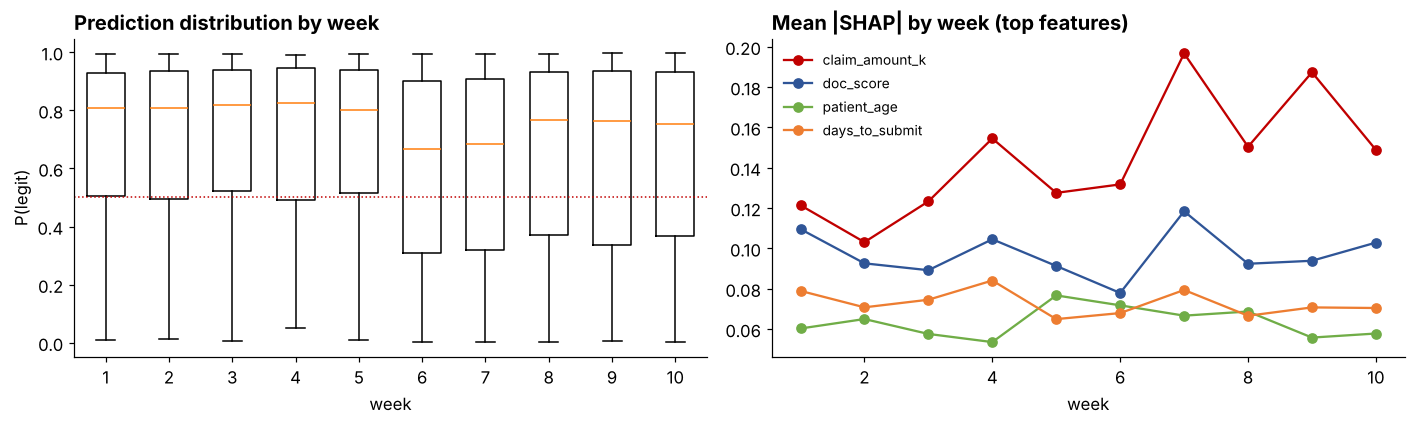

In [38]:
shap_rows = []
for w in range(1, 11):
    smp = stream[stream.week == w].sample(50, random_state=w)
    ph = np.array([exact_shap(r)[1] for r in smp[FEATURES].to_numpy(float)])
    shap_rows.append(pd.Series(np.abs(ph).mean(0), FEATURES, name=w))
shap_time = pd.DataFrame(shap_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].boxplot([stream.loc[stream.week == w, "p"] for w in range(1, 11)], positions=range(1, 11), widths=0.6, showfliers=False)
axes[0].axhline(0.5, color=RED, ls=":", lw=1); axes[0].set_xlabel("week"); axes[0].set_ylabel("P(legit)")
axes[0].set_title("Prediction distribution by week", loc="left")
for f, c in zip(["claim_amount_k", "doc_score", "patient_age", "days_to_submit"], [RED, NAVY, GREEN, ORANGE]):
    axes[1].plot(shap_time.index, shap_time[f], marker="o", color=c, label=f)
axes[1].set_xlabel("week"); axes[1].set_title("Mean |SHAP| by week (top features)", loc="left"); axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

Now **explore slices** to find who is being wrongly approved in weeks 8–10. Complete `slice_explorer`: bin `days_to_submit` into `["0-1", "2-7", "8-30"]` and `doc_score` into `["<0.6", "0.6-0.85", ">0.85"]`, and return the **false-approval rate** (`pred == 1` and `legit == 0`, divided by slice size) and the slice size for each (days_bin, doc_bin) slice.

In [39]:
def slice_explorer(df):
    # TODO F5: use pd.cut with bins [-1, 1, 7, 30] and [-0.01, 0.6, 0.85, 1.0] and the labels above
    #          return a DataFrame indexed by (days_bin, doc_bin) with columns false_approval_rate and n
    return None

sl_before = slice_explorer(stream[stream.week <= 7])
sl_after = slice_explorer(stream[stream.week >= 8])
F5_slice = None        # tuple (days_bin, doc_bin) with the biggest increase in false-approval rate, e.g. ("2-7", "<0.6")

In [40]:
grade("F5", 3, F5_slice, lambda v: tuple(map(str, v)) == ("0-1", ">0.85"), "look for the slice whose false-approval rate jumps after week 8")

if sl_before is not None and sl_after is not None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, s, t in [(axes[0], sl_before, "weeks 1–7"), (axes[1], sl_after, "weeks 8–10")]:
        m = s.false_approval_rate.unstack()
        ax.imshow(m, cmap="Reds", vmin=0, vmax=0.8)
        for i in range(m.shape[0]):
            for j in range(m.shape[1]):
                ax.text(j, i, f"{m.iloc[i, j]:.0%}\n(n={s.n.unstack().iloc[i, j]})", ha="center", va="center", fontsize=8)
        ax.set_xticks(range(3), m.columns); ax.set_yticks(range(3), m.index)
        ax.set_xlabel("doc_score"); ax.set_title(f"False-approval rate, {t}", loc="left")
    axes[0].set_ylabel("days_to_submit")
    plt.tight_layout(); plt.show()

⏳ F5: not attempted yet (3 marks)


✍️ **F5b .** Is the week-8 problem **data drift**, a **data-quality bug**, or **concept drift**? Justify with one piece of visual evidence.

*Your answer:*

---
## Part G · Incident report and reflection 
✍️ **G1 .** Write a short **incident report** for MediCover's model-risk committee (≤ 150 words). Cover: what happened (two incidents, with weeks), how each was detected (name the chart), who was affected, and one recommended action for each.

✍️ **G2 .** Reflection: name **one** visualization from this activity that you would put on AutoClaim's permanent monitoring dashboard and **one** you would use only for ad-hoc investigation. Justify each in one sentence using Munzner's *overview first, zoom and filter, details on demand*.

*G1:*

*G2:*